# Notebook 17 — SMOTE / Scaling Order Sensitivity (fast)

Same analysis, same Table 8 classifier configurations, same split and seeds. **Speed-ups:**
1. The SMOTE/PCA matrices of both orders are built in parallel and cached (`cache/matrices_*.npz`).
2. Single-threaded classifiers (MLP, AdaBoost, Decision Tree, QDA, LDA, Naive Bayes, …) are trained **in parallel**, slowest first; LightGBM and CatBoost (already multi-threaded) run afterwards with all cores.
3. Every fitted model's predictions are cached (`cache/<model>_<order>.npz`), so an interrupted run resumes — existing cache files from the previous run are reused.
4. The 24,000 paired-bootstrap macro-F1 computations are vectorised (identical results, seconds instead of minutes).

## Step 1 — Configuration

In [1]:
import os, time, json, warnings
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
warnings.filterwarnings("ignore")

DATASET_ROOT = "/home/ali/Desktop/Algerian_Lamiaceae_v3"
OUTPUT_DIR   = os.path.join(DATASET_ROOT, "results")
OUT_DIR      = os.path.join(OUTPUT_DIR, "smote_scaling_sensitivity_all12")
CACHE        = os.path.join(OUT_DIR, "cache"); os.makedirs(CACHE, exist_ok=True)
N_PCA, GLOBAL_SEED, N_BOOT = 300, 42, 1000
N_CPU        = os.cpu_count() or 4
N_PARALLEL   = max(2, min(6, N_CPU // 2))          # models trained at the same time
THREADS_PER  = max(1, N_CPU // N_PARALLEL)          # BLAS / n_jobs threads per parallel model
print(f"Output: {OUT_DIR} | CPUs: {N_CPU} | parallel models: {N_PARALLEL} x {THREADS_PER} threads")

Output: /home/ali/Desktop/Algerian_Lamiaceae_v3/results/smote_scaling_sensitivity_all12 | CPUs: 32 | parallel models: 6 x 5 threads


## Step 2 — Rebuild the Raw Fused Features and the Split (identical to Notebook 00)

In [2]:
def collect_records(root):                       # same order as Notebook 00
    recs = []
    for split in ["train", "val", "test"]:
        sd = Path(root) / split
        if not sd.exists(): continue
        for sp in sorted(d for d in sd.iterdir() if d.is_dir()):
            recs += [(str(p), sp.name, split) for p in sorted(sp.rglob("*")) if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    return recs

records = collect_records(DATASET_ROOT)
X_hc   = np.load(os.path.join(OUTPUT_DIR, "hc_features_cache.npz"), allow_pickle=True)["X"]
X_deep = np.load(os.path.join(OUTPUT_DIR, "deep_features_cache.npz"), allow_pickle=True)["X"]
assert X_hc.shape[0] == X_deep.shape[0] == len(records), "Feature caches do not match the images on disk -- re-run Notebook 00."
X_all  = np.concatenate([X_deep, X_hc], axis=1).astype(np.float64)
le     = LabelEncoder(); y_all = le.fit_transform([r[1] for r in records]); splits = np.array([r[2] for r in records])
X_train_raw, y_train = X_all[splits == "train"], y_all[splits == "train"]
X_test_raw,  y_test  = X_all[splits == "test"],  y_all[splits == "test"]
classes = np.arange(len(le.classes_)); K = len(classes)
print(f"Fused features: {X_all.shape} | train {X_train_raw.shape} | test {X_test_raw.shape}")

Fused features: (19145, 1609) | train (14407, 1609) | test (2366, 1609)


## Step 3 — How Heterogeneous Are the Feature Ranges?

In [3]:
var = X_train_raw.var(0); nd = X_deep.shape[1]
rows = [{"block": b, "n_features": s.stop - s.start, "share_of_raw_distance_%": round(100 * var[s].sum() / var.sum(), 2),
         "share_after_scaling_%": round(100 * (s.stop - s.start) / X_all.shape[1], 2)}
        for b, s in {"deep (EfficientNet-B3)": slice(0, nd), "handcrafted": slice(nd, X_all.shape[1])}.items()]
names = [f"deep_{i:04d}" for i in range(nd)] + [f"texture_{i:02d}" for i in range(31)] + [f"color_{i:02d}" for i in range(24)] \
        + [f"shape_{i:02d}" for i in range(12)] + [f"vein_{i:02d}" for i in range(6)]
top = np.argsort(var)[::-1][:10]; rng_ = np.ptp(X_train_raw, 0); nz = rng_[rng_ > 0]
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nRange ratio (largest / smallest non-constant feature): {nz.max() / nz.min():.3g}x\nTop-10 features by variance:")
for i in top: print(f"  {names[i]:<14} variance {var[i]:.4g}  ({100 * var[i] / var.sum():.2f}% of total)")
RANGE_DIAG = {"range_ratio": float(nz.max() / nz.min()), "top10_share_raw_%": float(100 * var[top].sum() / var.sum()), "blocks": rows}

                 block  n_features  share_of_raw_distance_%  share_after_scaling_%
deep (EfficientNet-B3)        1536                      1.8                  95.46
           handcrafted          73                     98.2                   4.54

Range ratio (largest / smallest non-constant feature): 2.92e+04x
Top-10 features by variance:
  color_04       variance 1669  (33.01% of total)
  color_08       variance 518.3  (10.25% of total)
  color_12       variance 508.8  (10.06% of total)
  color_03       variance 497  (9.83% of total)
  color_00       variance 402.5  (7.96% of total)
  color_01       variance 246.3  (4.87% of total)
  color_05       variance 207.8  (4.11% of total)
  color_09       variance 134.9  (2.67% of total)
  color_13       variance 129.2  (2.55% of total)
  color_20       variance 118.9  (2.35% of total)


## Step 4 — Training/Test Matrices for Both Orders (parallel, cached)

In [4]:
def build(order):
    f = os.path.join(CACHE, f"matrices_{order}.npz")
    if os.path.exists(f):
        z = np.load(f); return order, (z["Xtr"], z["ytr"], z["Xte"]), "cached"
    t0 = time.time(); k = max(1, min(5, int(np.bincount(y_train).min()) - 1))
    smote = SMOTE(random_state=GLOBAL_SEED, k_neighbors=k)
    sc1, pca, sc2 = StandardScaler(), PCA(n_components=min(N_PCA, X_all.shape[1] - 1), random_state=GLOBAL_SEED), StandardScaler()
    if order == "current":                                    # Notebook 00: SMOTE -> sc1 -> PCA -> sc2
        X_sm, y_sm = smote.fit_resample(X_train_raw, y_train)
        Xtr = sc2.fit_transform(pca.fit_transform(sc1.fit_transform(X_sm)))
    else:                                                     # revised: sc1 -> SMOTE -> PCA -> sc2
        X_sm, y_sm = smote.fit_resample(sc1.fit_transform(X_train_raw), y_train)
        Xtr = sc2.fit_transform(pca.fit_transform(X_sm))
    Xte = sc2.transform(pca.transform(sc1.transform(X_test_raw)))
    np.savez(f, Xtr=Xtr, ytr=y_sm, Xte=Xte)
    return order, (Xtr, y_sm, Xte), f"{time.time() - t0:.0f}s, PCA variance {100 * pca.explained_variance_ratio_.sum():.1f}%"

out = Parallel(n_jobs=2)(delayed(build)(o) for o in ["current", "revised"])
DATA = {o: d for o, d, _ in out}
for o, d, msg in out: print(f"[{o:<7}] {len(y_train):,} -> {len(d[1]):,} training samples ({msg})")
ORDER_LABEL = {"current": "SMOTE -> scaling (current)", "revised": "Scaling -> SMOTE (revised)"}

[current] 14,407 -> 35,000 training samples (99s, PCA variance 84.0%)
[revised] 14,407 -> 35,000 training samples (95s, PCA variance 85.2%)


## Step 5 — Train All Twelve Classifiers in Both Orders (Table 8 configurations)

Cached models are not retrained. The *current* rows must reproduce Table 8.

In [5]:
S = GLOBAL_SEED
CLASSIFIERS = {   # Optuna-tuned configurations of Table 8 (Notebooks 01-12)
    "MLP": lambda: MLPClassifier(hidden_layer_sizes=(916,), alpha=8.32247350862405e-05, learning_rate_init=1.0968703180283828e-05,
                                 batch_size=128, max_iter=300, random_state=S, early_stopping=True),
    "LightGBM": lambda: LGBMClassifier(learning_rate=0.03195281813216447, num_leaves=43, n_estimators=424, min_child_samples=40,
                                       subsample=0.617536148867388, colsample_bytree=0.45622709459234523, reg_lambda=0.0022598483504384496,
                                       subsample_freq=1, class_weight="balanced", random_state=S, verbose=-1, n_jobs=16, force_col_wise=True),
    "Logistic Regression": lambda: LogisticRegression(C=2.883745233291561, penalty="l1", solver="saga", max_iter=1000,
                                                      random_state=S, class_weight="balanced", n_jobs=THREADS_PER),
    "SVM-LinearSVC": lambda: CalibratedClassifierCV(LinearSVC(C=0.0019517224641449498, max_iter=3000, random_state=S,
                                                              class_weight="balanced"), cv=3, n_jobs=THREADS_PER),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=480, max_depth=34, min_samples_leaf=4, max_features="log2",
                                                    random_state=S, n_jobs=THREADS_PER, class_weight="balanced"),
    "CatBoost": lambda: CatBoostClassifier(iterations=761, learning_rate=0.10017558909932621, depth=8, l2_leaf_reg=0.04796829933533339,
                                           border_count=237, random_seed=S, verbose=0, auto_class_weights="Balanced", task_type="CPU"),
    "LDA": lambda: LinearDiscriminantAnalysis(solver="lsqr", shrinkage=None),
    "QDA": lambda: QuadraticDiscriminantAnalysis(reg_param=0.13932037674715556),
    "KNN": lambda: KNeighborsClassifier(n_neighbors=22, weights="distance", metric="cosine", algorithm="brute", n_jobs=THREADS_PER),
    "AdaBoost": lambda: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3, random_state=S), n_estimators=118,
                                           learning_rate=0.32950253088857584, random_state=S),
    "Decision Tree": lambda: DecisionTreeClassifier(max_depth=50, min_samples_split=48, min_samples_leaf=20, criterion="log_loss",
                                                    ccp_alpha=6.848925625719247e-05, random_state=S, class_weight="balanced"),
    "Naive Bayes": lambda: GaussianNB(var_smoothing=3.122348867288781e-08),
}
TABLE8_WF1 = {"MLP": 91.88, "LightGBM": 91.45, "Logistic Regression": 91.24, "SVM-LinearSVC": 91.16, "Random Forest": 90.67,
              "CatBoost": 90.36, "LDA": 89.88, "QDA": 89.87, "KNN": 88.08, "AdaBoost": 83.47, "Decision Tree": 78.60, "Naive Bayes": 73.94}
SELF_THREADED = {"LightGBM", "CatBoost"}                       # run alone afterwards, with all cores
SLOW_FIRST    = ["MLP", "AdaBoost", "SVM-LinearSVC", "Random Forest", "Logistic Regression", "KNN",
                 "Decision Tree", "QDA", "LDA", "Naive Bayes"]

def cache_file(name, order): return os.path.join(CACHE, f"{name.replace(' ', '_')}_{order}.npz")

def fit_one(name, order, Xtr, ytr, Xte, threads):
    t0 = time.time()
    with threadpool_limits(threads):
        model = CLASSIFIERS[name]().fit(Xtr, ytr)
        p, pr = np.asarray(model.predict(Xte)).ravel().astype(int), model.predict_proba(Xte)
    np.savez_compressed(cache_file(name, order), p=p, pr=pr)
    return f"{name} | {order}: {time.time() - t0:.0f}s"

todo = [(n, o) for n in SLOW_FIRST for o in ["current", "revised"] if not os.path.exists(cache_file(n, o))]
n_cached = sum(os.path.exists(cache_file(n, o)) for n in CLASSIFIERS for o in DATA)
print(f"{n_cached} of 24 models cached; training {len(todo)} in parallel, then the multi-threaded ones ...", flush=True)
T0 = time.time()
tasks = (delayed(fit_one)(n, o, *DATA[o], THREADS_PER) for n, o in todo)     # arrays are memory-mapped to the workers
try:    results = Parallel(n_jobs=N_PARALLEL, return_as="generator_unordered")(tasks)
except (TypeError, ValueError): results = Parallel(n_jobs=N_PARALLEL)(tasks)   # joblib < 1.4
for msg in results:
    print(f"  done: {msg}  (elapsed {(time.time() - T0) / 60:.1f} min)", flush=True)
for n in SELF_THREADED:
    for o in ["current", "revised"]:
        if not os.path.exists(cache_file(n, o)): print(f"  done: {fit_one(n, o, *DATA[o], N_CPU)}", flush=True)

def metrics(y, p, pr):
    return {"Accuracy": accuracy_score(y, p) * 100, "Macro_P": precision_score(y, p, average="macro", zero_division=0) * 100,
            "Macro_R": recall_score(y, p, average="macro", zero_division=0) * 100,
            "Macro_F1": f1_score(y, p, average="macro", zero_division=0) * 100,
            "Weighted_F1": f1_score(y, p, average="weighted", zero_division=0) * 100,
            "Macro_AUC": roc_auc_score(y, pr, multi_class="ovr", average="macro", labels=classes) * 100}
rows, preds = [], {}
for name in CLASSIFIERS:
    for order in ["current", "revised"]:
        z = np.load(cache_file(name, order)); preds[(name, order)] = z["p"]
        rows.append({"Classifier": name, "Order": ORDER_LABEL[order], **{m: round(v, 2) for m, v in metrics(y_test, z["p"], z["pr"]).items()}})
res = pd.DataFrame(rows)
print(f"\nAll 24 models ready in {(time.time() - T0) / 60:.1f} min\n")
chk = pd.DataFrame({"this_run": res[res.Order == ORDER_LABEL["current"]].set_index("Classifier").Weighted_F1, "Table8": pd.Series(TABLE8_WF1)})
chk["diff"] = (chk.this_run - chk.Table8).round(2)
print("Reproduction of Table 8 (weighted F1, current order):\n" + chk.to_string())
if chk["diff"].abs().max() > 0.3: print("WARNING: some 'current' results differ from Table 8 by > 0.3 points.")

5 of 24 models cached; training 17 in parallel, then the multi-threaded ones ...
  done: SVM-LinearSVC | current: 16s  (elapsed 0.4 min)
  done: SVM-LinearSVC | revised: 18s  (elapsed 0.4 min)
  done: KNN | current: 14s  (elapsed 0.7 min)
  done: KNN | revised: 13s  (elapsed 0.9 min)
  done: Decision Tree | current: 84s  (elapsed 2.3 min)
  done: Random Forest | current: 160s  (elapsed 2.8 min)
  done: Random Forest | revised: 160s  (elapsed 2.8 min)
  done: QDA | current: 9s  (elapsed 2.9 min)
  done: LDA | current: 2s  (elapsed 3.0 min)
  done: QDA | revised: 10s  (elapsed 3.0 min)
  done: Naive Bayes | current: 0s  (elapsed 3.0 min)
  done: LDA | revised: 1s  (elapsed 3.0 min)
  done: Naive Bayes | revised: 0s  (elapsed 3.0 min)
  done: Decision Tree | revised: 69s  (elapsed 3.4 min)
  done: Logistic Regression | revised: 1160s  (elapsed 19.7 min)


/home/ali/Downloads/or/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


  done: AdaBoost | revised: 1707s  (elapsed 28.6 min)
  done: AdaBoost | current: 1747s  (elapsed 29.2 min)
  done: CatBoost | revised: 581s

All 24 models ready in 38.9 min

Reproduction of Table 8 (weighted F1, current order):
                     this_run  Table8  diff
MLP                     91.88   91.88  0.00
LightGBM                91.24   91.45 -0.21
Logistic Regression     91.25   91.24  0.01
SVM-LinearSVC           91.16   91.16  0.00
Random Forest           90.44   90.67 -0.23
CatBoost                91.22   90.36  0.86
LDA                     89.88   89.88  0.00
QDA                     89.87   89.87  0.00
KNN                     88.08   88.08  0.00
AdaBoost                82.53   83.47 -0.94
Decision Tree           78.60   78.60  0.00
Naive Bayes             73.94   73.94  0.00


## Step 6 — Paired-Bootstrap Comparison (vectorised)

Δ = revised − current; 95% CI from 1,000 resamples of the same test images. *Significant* = CI excludes 0.

In [6]:
IDX = np.random.RandomState(GLOBAL_SEED).randint(0, len(y_test), (N_BOOT, len(y_test)))   # same resamples as before
def boot_macro_f1(p):
    """Macro-F1 (sklearn definition: classes present in y_true or y_pred) for every bootstrap resample at once."""
    codes = (y_test[IDX] * K + p[IDX]) + (np.arange(N_BOOT) * K * K)[:, None]
    cm = np.bincount(codes.ravel(), minlength=N_BOOT * K * K).reshape(N_BOOT, K, K)
    tp = np.einsum("bii->bi", cm); den = 2 * tp + (cm.sum(1) - tp) + (cm.sum(2) - tp)
    f1 = np.divide(2 * tp, den, out=np.zeros(den.shape), where=den > 0)
    return 100 * f1.sum(1) / (den > 0).sum(1)

cmp_rows = []
for name in CLASSIFIERS:
    a, b = preds[(name, "current")], preds[(name, "revised")]
    r_c = res[(res.Classifier == name) & (res.Order == ORDER_LABEL["current"])].iloc[0]
    r_r = res[(res.Classifier == name) & (res.Order == ORDER_LABEL["revised"])].iloc[0]
    lo, hi = np.percentile(boot_macro_f1(b) - boot_macro_f1(a), [2.5, 97.5])
    cmp_rows.append({"Classifier": name, "MacroF1_current": r_c.Macro_F1, "MacroF1_revised": r_r.Macro_F1,
                     "Delta_MacroF1": round(r_r.Macro_F1 - r_c.Macro_F1, 2), "Delta_95CI": f"[{lo:.2f}, {hi:.2f}]",
                     "Significant": bool(not (lo <= 0 <= hi)), "Delta_WeightedF1": round(r_r.Weighted_F1 - r_c.Weighted_F1, 2),
                     "Delta_Accuracy": round(r_r.Accuracy - r_c.Accuracy, 2), "Agreement_%": round(100 * (a == b).mean(), 2)})
cmp_df = pd.DataFrame(cmp_rows)
cmp_df["Rank_current"] = cmp_df.MacroF1_current.rank(ascending=False, method="min").astype(int)
cmp_df["Rank_revised"] = cmp_df.MacroF1_revised.rank(ascending=False, method="min").astype(int)
pd.set_option("display.width", 220); print(res.to_string(index=False)); print(); print(cmp_df.to_string(index=False))
best_c = cmp_df.loc[cmp_df.MacroF1_current.idxmax(), "Classifier"]; best_r = cmp_df.loc[cmp_df.MacroF1_revised.idxmax(), "Classifier"]
print(f"\nBest classifier -- current: {best_c} | revised: {best_r}")

         Classifier                      Order  Accuracy  Macro_P  Macro_R  Macro_F1  Weighted_F1  Macro_AUC
                MLP SMOTE -> scaling (current)     91.80    91.59    92.29     91.93        91.88      99.13
                MLP Scaling -> SMOTE (revised)     89.56    86.54    91.66     88.95        89.77      98.61
           LightGBM SMOTE -> scaling (current)     91.12    89.96    91.85     90.87        91.24      99.08
           LightGBM Scaling -> SMOTE (revised)     91.59    90.80    92.38     91.56        91.69      99.06
Logistic Regression SMOTE -> scaling (current)     91.12    89.32    91.73     90.48        91.25      99.01
Logistic Regression Scaling -> SMOTE (revised)     90.96    89.34    91.68     90.47        91.07      98.99
      SVM-LinearSVC SMOTE -> scaling (current)     91.04    89.11    92.47     90.69        91.16      98.82
      SVM-LinearSVC Scaling -> SMOTE (revised)     90.41    88.41    91.65     89.96        90.55      98.82
      Random Forest

## Step 7 — Figure and Saved Results

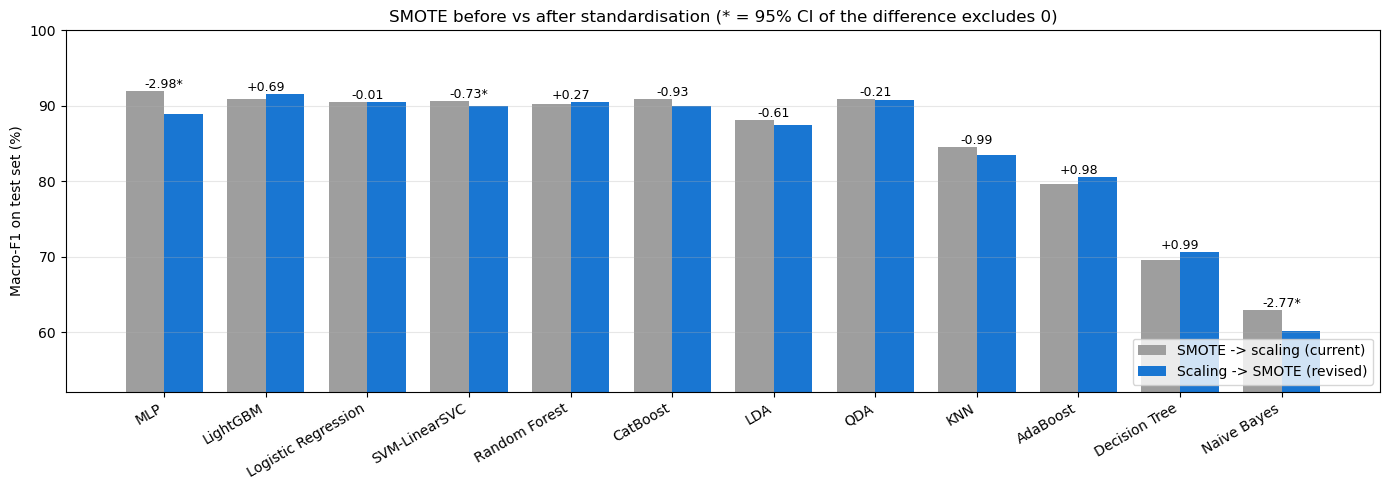

Because SMOTE was applied to the unstandardised 1,609-dimensional fused feature vector (feature ranges differed by a factor of 2.92e+04), we repeated the classification with standardisation applied before SMOTE (sc1 -> SMOTE -> PCA-300 -> sc2), keeping the split, classifier settings and test set unchanged. Macro-F1 changed by at most 2.98 percentage points (MLP: -2.98, LightGBM: +0.69, Logistic Regression: -0.01, SVM-LinearSVC: -0.73, Random Forest: +0.27, CatBoost: -0.93, LDA: -0.61, QDA: -0.21, KNN: -0.99, AdaBoost: +0.98, Decision Tree: +0.99, Naive Bayes: -2.77); 3 of 12 differences had a paired-bootstrap 95% CI excluding zero, test predictions agreed in 70.7-98.1% of images, and the best-performing classifier was different (Table S_).

Saved table, summary, figure and text in /home/ali/Desktop/Algerian_Lamiaceae_v3/results/smote_scaling_sensitivity_all12


In [7]:
fig, ax = plt.subplots(figsize=(14, 5)); x = np.arange(len(cmp_df)); w = 0.38
ax.bar(x - w / 2, cmp_df.MacroF1_current, w, label=ORDER_LABEL["current"], color="#9e9e9e")
ax.bar(x + w / 2, cmp_df.MacroF1_revised, w, label=ORDER_LABEL["revised"], color="#1976d2")
for i, r in cmp_df.iterrows():
    ax.text(i, max(r.MacroF1_current, r.MacroF1_revised) + 0.4, f"{r.Delta_MacroF1:+.2f}{'*' if r.Significant else ''}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(cmp_df.Classifier, rotation=30, ha="right")
ax.set_ylim(max(0, min(cmp_df.MacroF1_current.min(), cmp_df.MacroF1_revised.min()) - 8), 100); ax.set_ylabel("Macro-F1 on test set (%)")
ax.set_title("SMOTE before vs after standardisation (* = 95% CI of the difference excludes 0)"); ax.legend(loc="lower right"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
for ext in ("png", "pdf"): fig.savefig(os.path.join(OUT_DIR, f"smote_order_sensitivity.{ext}"), dpi=300, bbox_inches="tight")
plt.show()

res.to_csv(os.path.join(OUT_DIR, "smote_order_all_metrics.csv"), index=False)
cmp_df.to_csv(os.path.join(OUT_DIR, "smote_order_comparison.csv"), index=False)
max_abs = cmp_df.Delta_MacroF1.abs().max(); n_sig = int(cmp_df.Significant.sum())
txt = (f"Because SMOTE was applied to the unstandardised 1,609-dimensional fused feature vector (feature ranges differed "
       f"by a factor of {RANGE_DIAG['range_ratio']:.3g}), we repeated the classification with standardisation applied "
       f"before SMOTE (sc1 -> SMOTE -> PCA-{N_PCA} -> sc2), keeping the split, classifier settings and test set unchanged. "
       f"Macro-F1 changed by at most {max_abs:.2f} percentage points "
       f"({', '.join(f'{r.Classifier}: {r.Delta_MacroF1:+.2f}' for r in cmp_df.itertuples())}); {n_sig} of {len(cmp_df)} "
       f"differences had a paired-bootstrap 95% CI excluding zero, test predictions agreed in "
       f"{cmp_df['Agreement_%'].min():.1f}-{cmp_df['Agreement_%'].max():.1f}% of images, and the best-performing "
       f"classifier was {'unchanged' if best_c == best_r else 'different'} (Table S_).")
json.dump({"range_diagnostics": RANGE_DIAG, "max_abs_delta_macroF1": float(max_abs), "n_significant": n_sig,
           "best_current": best_c, "best_revised": best_r, "comparison": cmp_rows},
          open(os.path.join(OUT_DIR, "smote_order_summary.json"), "w"), indent=2, default=str)
open(os.path.join(OUT_DIR, "smote_order_text.txt"), "w").write(txt)
print(txt + f"\n\nSaved table, summary, figure and text in {OUT_DIR}")